In [2]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU - change runtime type")

from google.colab import drive, userdata
drive.mount("/content/drive")

tok = userdata.get("GH_TOKEN")
!rm -rf /content/repo
!git clone -q https://{tok}@github.com/mennanasa12-cloud/paradox_perception.git /content/repo
!pip -q install ultralytics pyyaml

!mkdir -p /content/rc
!wget -c --tries=10 --timeout=60 -O /content/rc/Dataset_yolo.zip "https://zenodo.org/records/14673237/files/Dataset_yolo.zip?download=1"
!md5sum /content/rc/Dataset_yolo.zip
!cd /content/rc && unzip -q -o Dataset_yolo.zip
!mkdir -p /content/drive/MyDrive/paradox && cp /content/rc/Dataset_yolo.zip /content/drive/MyDrive/paradox/rocks_craters_yolo.zip

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.9 MB/s eta 0:00:00
--2026-10-11 08:33:09--  https://zenodo.org/records/14673237/files/Dataset_yolo.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.184.103.118, 188.184.98.114, 188.185.43.153, ...
Connecting to zenodo.org (zenodo.org)|188.184.103.118|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 186819579 (178M) [application/octet-stream]
Saving to: ‘/content/rc/Dataset_yolo.zip’

/content/rc/Dataset 100%[===================>] 178.16M  1.20MB/s    in 2m 5s   

2026-10-11 08:35:15 (1.43 MB/s) - ‘/content/rc/Dataset_yolo.zip’ saved [186819579/186819579]

ea48137b90a6a840f8195d16017f7866  /content/rc/D

In [3]:
!find /content/rc -maxdepth 3 -type d | head -20
!find /content/rc -name "*.yaml" | head
!cat $(find /content/rc -name "*.yaml" | head -1)

import glob
lab = sorted(glob.glob("/content/rc/**/labels/**/*.txt", recursive=True))
print(len(lab), "label files")
for f in lab[:3]:
    print(f); print(open(f).read()[:300])

/content/rc
/content/rc/Dataset_yolo
/content/rc/Dataset_yolo/test
/content/rc/Dataset_yolo/test/labels
/content/rc/Dataset_yolo/test/images
/content/rc/Dataset_yolo/train
/content/rc/Dataset_yolo/train/labels
/content/rc/Dataset_yolo/train/images
/content/rc/Dataset_yolo/valid
/content/rc/Dataset_yolo/valid/labels
/content/rc/Dataset_yolo/valid/images
/content/rc/Dataset_yolo/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['crater', 'rock']

roboflow:
  workspace: dsad-omghq
  project: combined-mgeca
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/dsad-omghq/combined-mgeca/dataset/28354 label files
/content/rc/Dataset_yolo/test/labels/rgb_0_png_jpg.rf.a9a4c83a908e9f3da8cde77abc251cbf.txt
1 0.1653796875 0.325415625 0.14002187500000002 0.35391875 0.11907343749999999 0.3943 0.1212796875 0.40380000000000005 0.10253593750000001 0.4323046875 0.093715625 0.46793281249999996 0.09592031250000001 0.5083140625 0.10694531249999999 0

In [4]:
import yaml
cfg = {"path": "/content/rc/Dataset_yolo", "train": "train/images", "val": "valid/images",
       "test": "test/images", "nc": 2, "names": ["crater", "rock"]}
yaml.safe_dump(cfg, open("/content/rc/rocks.yaml", "w"))

In [5]:
from collections import Counter
from pathlib import Path
for s in ["train", "valid", "test"]:
    c = Counter(int(l.split()[0]) for f in Path(f"/content/rc/Dataset_yolo/{s}/labels").glob("*.txt") for l in open(f) if l.strip())
    n = len(list(Path(f"/content/rc/Dataset_yolo/{s}/images").glob("*")))
    print(s, n, "images", dict(c))

train 7734 images {1: 15097, 0: 6352}
valid 313 images {1: 738, 0: 219}
test 307 images {1: 879, 0: 143}


In [6]:
from ultralytics import YOLO
model = YOLO("yolov8s.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [7]:
_ = model.train(data="/content/rc/rocks.yaml", epochs=2, imgsz=640, batch=16, fraction=0.1,
                project="/content/drive/MyDrive/paradox/checkpoints", name="yolo_smoke", exist_ok=True)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rc/rocks.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_smoke, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

In [8]:
from ultralytics import YOLO
model = YOLO("yolov8s.pt")
_ = model.train(data="/content/rc/rocks.yaml", epochs=30, imgsz=640, batch=16, patience=10,
                project="/content/drive/MyDrive/paradox/checkpoints", name="yolov8s_rocks", exist_ok=True)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rc/rocks.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_rocks, nbs=64, nms=None, opset=None, optimize=False, optimiz

In [9]:
from google.colab import drive, userdata
drive.mount("/content/drive")

tok = userdata.get("GH_TOKEN")
!rm -rf /content/repo
!git clone -q https://{tok}@github.com/mennanasa12-cloud/paradox_perception.git /content/repo

!find /content/drive/MyDrive -name "*.ipynb" -not -path "*/.Trash*" 2>/dev/null | head -20

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/task3_rock_detection.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/continuouschatbots.ipynb
/content/drive/MyDrive/Colab Notebooks/update_models.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/FineTuning.ipynb
/content/drive/MyDrive/Colab Notebooks/FineTuning (1).ipynb
/content/drive/MyDrive/Colab Notebooks/FineTuning__1_.ipynb
/content/drive/MyDrive/Colab Notebooks/FinalFineTuning (1) (2).ipynb
/content/drive/MyDrive/Colab Notebooks/FinalFineTuning (1) (1).ipynb
/content/drive/MyDrive/Colab Notebooks/FinalFineTuning (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Face_Recognition_Attendence.ipynb
/content/drive/MyDrive/Colab Notebooks/FaceDetectionUsingHaarCasc

In [10]:
from google.colab import drive
drive.mount("/content/drive")

import os
assert os.path.exists("/content/drive/MyDrive/paradox/rocks_craters_yolo.zip"), "Drive not mounted or file missing"

!mkdir -p /content/rc
!cp /content/drive/MyDrive/paradox/rocks_craters_yolo.zip /content/rc/Dataset_yolo.zip
!cd /content/rc && unzip -q -o Dataset_yolo.zip
!ls /content/rc/Dataset_yolo

import yaml
yaml.safe_dump({"path": "/content/rc/Dataset_yolo", "train": "train/images", "val": "valid/images",
                "test": "test/images", "nc": 2, "names": ["crater", "rock"]}, open("/content/rc/rocks.yaml", "w"))
!pip -q install ultralytics

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data.yaml  test  train	valid


In [11]:
from ultralytics import YOLO
m = YOLO("/content/drive/MyDrive/paradox/checkpoints/yolov8s_rocks/weights/best.pt")
_ = m.val(data="/content/rc/rocks.yaml", split="test")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 945.8±251.8 MB/s, size: 23.9 KB)
val: Scanning /content/rc/Dataset_yolo/test/labels... 307 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 307/307 1.4Kit/s 0.2s
val: New cache created: /content/rc/Dataset_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 2.4it/s 8.5s
                   all        307       1022      0.951      0.966      0.985      0.912
                crater         96        143      0.979      0.962      0.986      0.909
                  rock        302        879      0.924       0.97      0.983      0.915
Speed: 3.0ms preprocess, 11.3ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/runs/detect/val


In [12]:
from pathlib import Path
base = lambda p: p.name.split(".rf.")[0]
S = {s: {base(p) for p in Path(f"/content/rc/Dataset_yolo/{s}/images").glob("*")} for s in ["train", "valid", "test"]}
print({s: len(v) for s, v in S.items()})
print("train&valid:", len(S["train"] & S["valid"]), "| train&test:", len(S["train"] & S["test"]), "| valid&test:", len(S["valid"] & S["test"]))

{'train': 989, 'valid': 277, 'test': 268}
train&valid: 259 | train&test: 249 | valid&test: 75


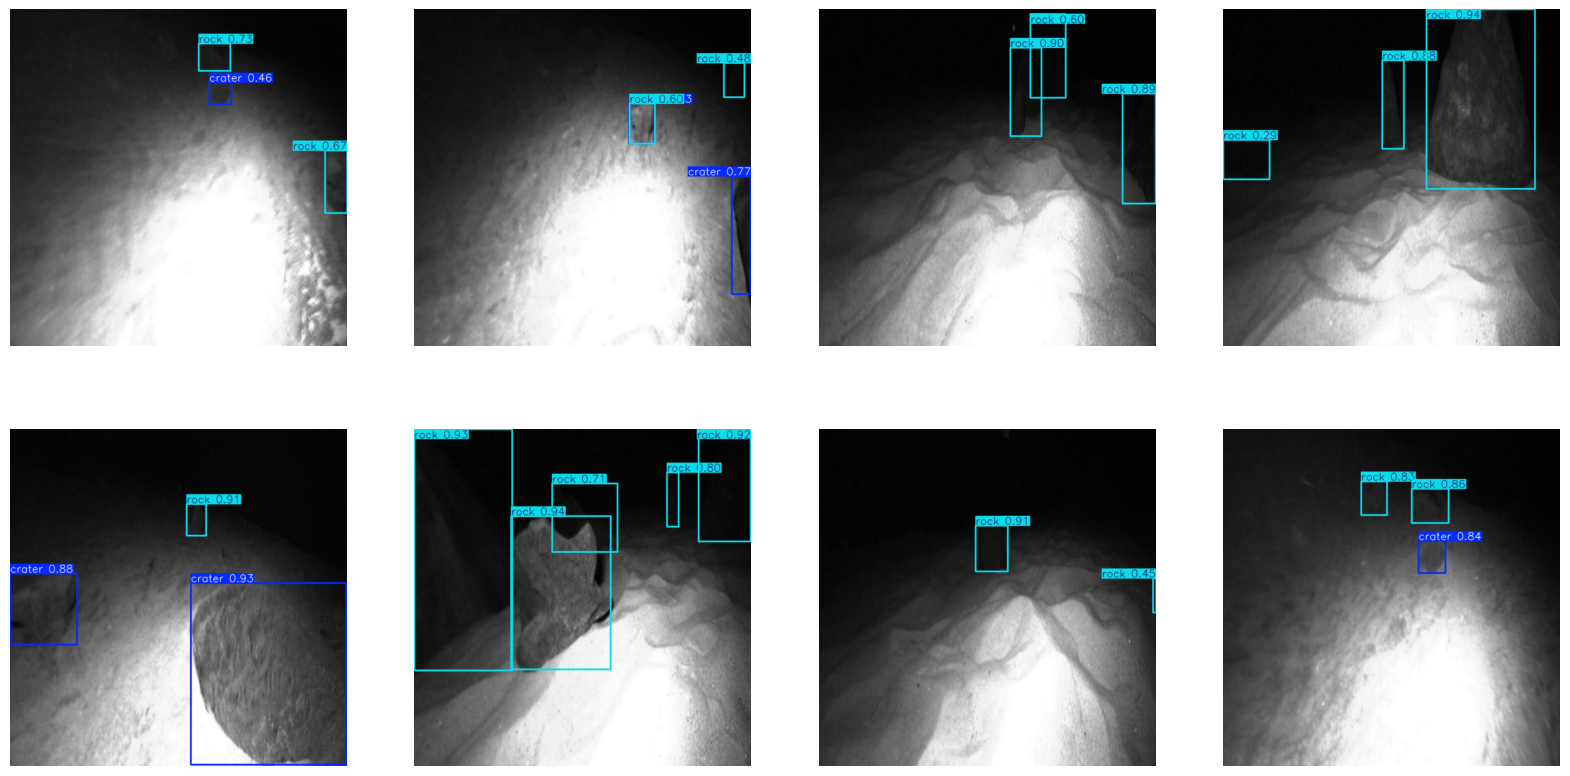

In [15]:
import os, random, glob, matplotlib.pyplot as plt
from ultralytics import YOLO

# Ensure we have our model loaded
m = YOLO("/content/drive/MyDrive/paradox/checkpoints/yolov8s_rocks/weights/best.pt")

# Extract the correct dataset to /content/rc/ if not already present
if not os.path.exists("/content/rc/Dataset_yolo"):
    !mkdir -p /content/rc && cp /content/drive/MyDrive/paradox/rocks_craters_yolo.zip /content/rc/Dataset_yolo.zip
    !cd /content/rc && unzip -q -o Dataset_yolo.zip

files = glob.glob("/content/rc/Dataset_yolo/test/images/*")
if len(files) < 8:
    print(f"Warning: Found only {len(files)} images. Showing all available.")
    num_samples = len(files)
else:
    num_samples = 8

if num_samples > 0:
    selected_files = random.sample(files, num_samples)
    cols = min(4, num_samples)
    rows = (num_samples + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols, figsize=(20, 5 * rows))
    axes = ax.ravel() if num_samples > 1 else [ax]
    for a, f in zip(axes, selected_files):
        a.imshow(m.predict(f, conf=0.25, verbose=False)[0].plot()[..., ::-1])
        a.axis("off")
    # Hide any unused axes
    for a in axes[num_samples:]:
        a.axis("off")
    plt.show()
else:
    print("No images found to display. Please verify that the dataset exists and was correctly extracted.")

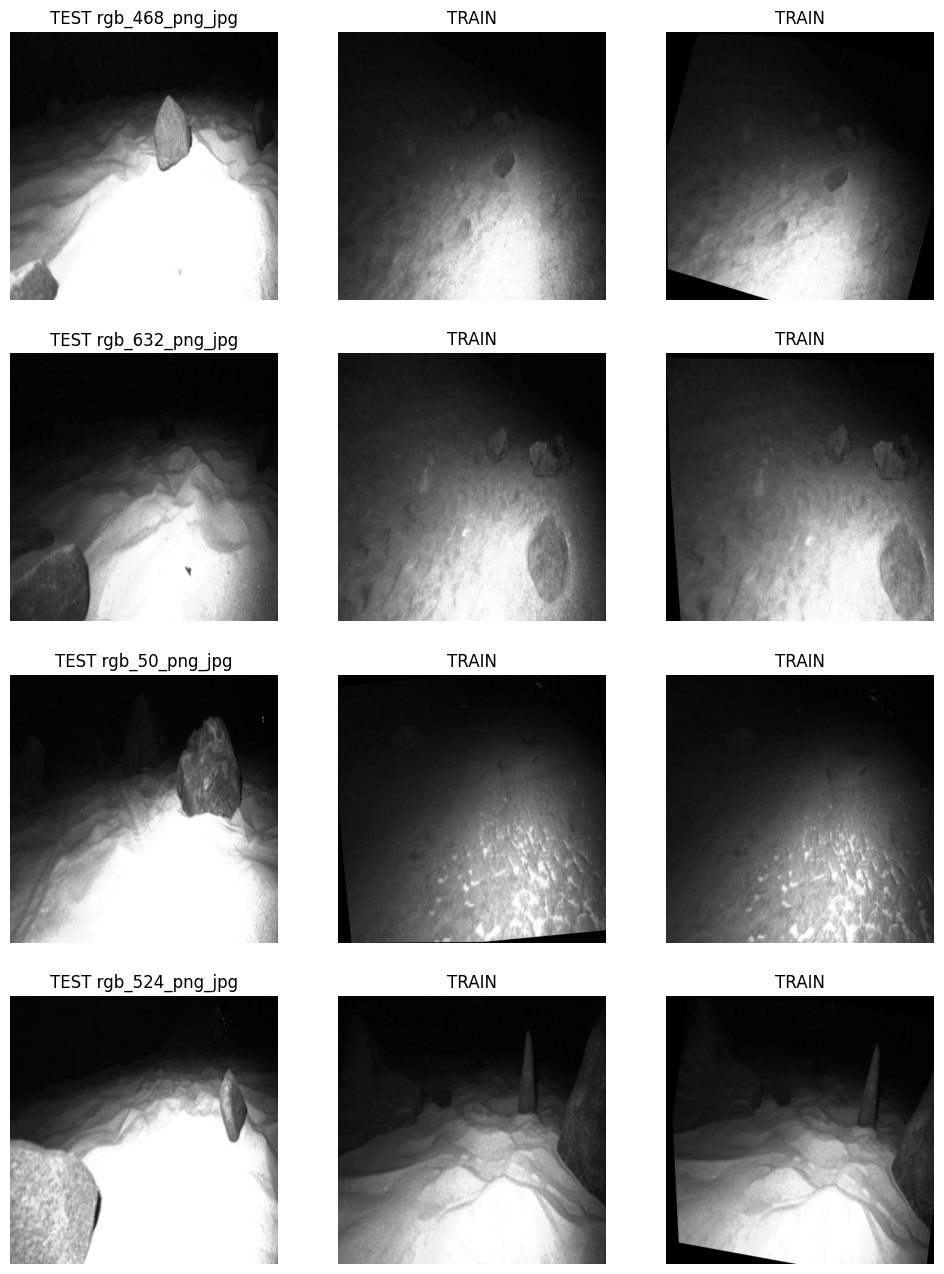

In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
base = lambda p: p.name.split(".rf.")[0]
R = Path("/content/rc/Dataset_yolo")
tr = {}
for p in (R/"train"/"images").glob("*"): tr.setdefault(base(p), []).append(p)
common = [p for p in (R/"test"/"images").glob("*") if base(p) in tr][:4]
fig, ax = plt.subplots(4, 3, figsize=(12, 16))
for r, tp in enumerate(common):
    ax[r][0].imshow(Image.open(tp)); ax[r][0].set_title("TEST " + base(tp))
    for c, trp in enumerate(tr[base(tp)][:2], start=1):
        ax[r][c].imshow(Image.open(trp)); ax[r][c].set_title("TRAIN")
for a in ax.ravel(): a.axis("off")
plt.show()

In [17]:
from pathlib import Path
import shutil, random, yaml
SRC, DST = Path("/content/rc/Dataset_yolo"), Path("/content/rc/Dataset_clean")
base = lambda p: p.name.split(".rf.")[0]

groups = {}
for s in ["train", "valid", "test"]:
    for p in (SRC/s/"images").glob("*"):
        groups.setdefault(base(p), []).append((s, p))

names = sorted(groups); random.Random(0).shuffle(names)
n = len(names); c1, c2 = int(n*0.8), int(n*0.9)
split_of = {g: ("train" if i < c1 else "valid" if i < c2 else "test") for i, g in enumerate(names)}

shutil.rmtree(DST, ignore_errors=True)
for s in ["train", "valid", "test"]:
    (DST/s/"images").mkdir(parents=True); (DST/s/"labels").mkdir(parents=True)
for g, items in groups.items():
    d = split_of[g]
    for s, p in items:
        shutil.copy(p, DST/d/"images"/p.name)
        lab = SRC/s/"labels"/(p.stem + ".txt")
        if lab.exists(): shutil.copy(lab, DST/d/"labels"/lab.name)

yaml.safe_dump({"path": str(DST), "train": "train/images", "val": "valid/images", "test": "test/images",
                "nc": 2, "names": ["crater", "rock"]}, open("/content/rc/rocks_clean.yaml", "w"))
for s in ["train", "valid", "test"]:
    print(s, len(list((DST/s/"images").glob("*"))), "images")

train 6664 images
valid 804 images
test 886 images


[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
test images with distance < 0.3: 886 of 886


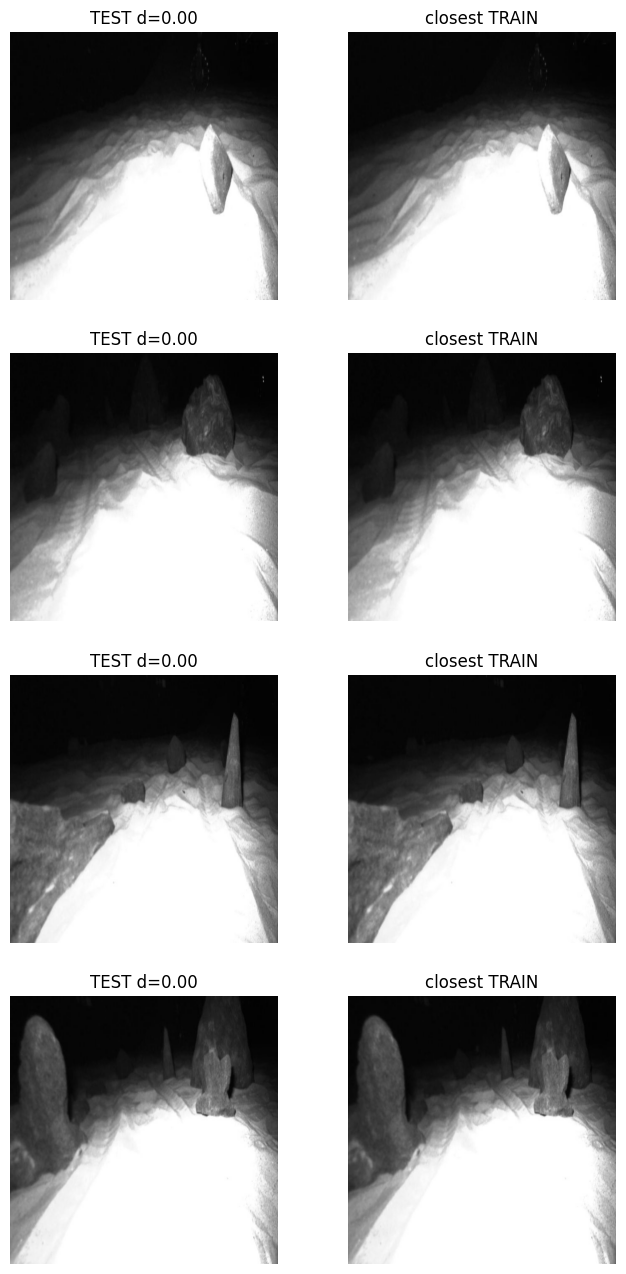

In [18]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

R = Path("/content/rc/Dataset_clean")
def vec(p):
    a = np.asarray(Image.open(p).convert("L").resize((24, 24)), dtype=np.float32)
    return (a - a.mean()) / (a.std() + 1e-6)

tr_paths = sorted((R/"train"/"images").glob("*"))
te_paths = sorted((R/"test"/"images").glob("*"))
tr = np.stack([vec(p).ravel() for p in tr_paths])

res = []
for p in te_paths:
    a = vec(p)
    d = np.minimum(np.mean((tr - a.ravel())**2, axis=1), np.mean((tr - a[:, ::-1].ravel())**2, axis=1))
    i = int(d.argmin()); res.append((float(d[i]), p, tr_paths[i]))
res.sort(key=lambda r: r[0])

print([round(r[0], 3) for r in res[:10]])
print("test images with distance < 0.3:", sum(r[0] < 0.3 for r in res), "of", len(res))

fig, ax = plt.subplots(4, 2, figsize=(8, 16))
for k, (d, tp, rp) in enumerate(res[:4]):
    ax[k][0].imshow(Image.open(tp)); ax[k][0].set_title(f"TEST d={d:.2f}")
    ax[k][1].imshow(Image.open(rp)); ax[k][1].set_title("closest TRAIN")
for a in ax.ravel(): a.axis("off")
plt.show()

retrain with verified clean split because data leakage happened

In [19]:
!cd /content/rc && rm -rf stage && mkdir stage && cp -r Dataset_clean stage/Dataset_yolo && cp Dataset_yolo/data.yaml stage/Dataset_yolo/

In [20]:
!cd /content/rc/stage && zip -qr rocks_craters_yolo.zip Dataset_yolo

In [21]:
!cp /content/rc/stage/rocks_craters_yolo.zip /content/drive/MyDrive/paradox/rocks_craters_yolo.zip

In [22]:
!ls -lh /content/rc/stage/rocks_craters_yolo.zip /content/drive/MyDrive/paradox/rocks_craters_yolo.zip

-rw------- 1 root root 175M Oct 11 09:53 /content/drive/MyDrive/paradox/rocks_craters_yolo.zip
-rw-r--r-- 1 root root 175M Oct 11 09:53 /content/rc/stage/rocks_craters_yolo.zip


In [23]:
from pathlib import Path
import numpy as np
from PIL import Image
R = Path("/content/rc/Dataset_yolo")
paths = sorted(p for s in ["train", "valid", "test"] for p in (R/s/"images").glob("*"))
def vec(p):
    a = np.asarray(Image.open(p).convert("L").resize((24, 24)), dtype=np.float32)
    return (a - a.mean()) / (a.std() + 1e-6)
A = [vec(p) for p in paths]
X = np.stack([a.ravel() for a in A])
Xf = np.stack([a[:, ::-1].ravel() for a in A])
print(X.shape)

(8354, 576)


In [24]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
n = len(X)
sq = (X ** 2).sum(1)
rows, cols = [], []
for i in range(0, n, 500):
    d1 = (sq[i:i+500, None] + sq[None, :] - 2 * X[i:i+500] @ X.T) / X.shape[1]
    d2 = (sq[i:i+500, None] + sq[None, :] - 2 * X[i:i+500] @ Xf.T) / X.shape[1]
    r, c = np.where(np.minimum(d1, d2) < 0.02)
    rows.append(r + i); cols.append(c)
rows = np.concatenate(rows); cols = np.concatenate(cols)
G = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
ngroups, label = connected_components(G, directed=False)
sizes = np.bincount(label)
print(ngroups, "groups | biggest group:", sizes.max(), "images")

3481 groups | biggest group: 2735 images


In [25]:
import shutil, random
DST = Path("/content/rc/Dataset_clean")
assert len({p.name for p in paths}) == len(paths)
big = [g for g in range(ngroups) if sizes[g] > 200]
rest = [g for g in range(ngroups) if sizes[g] <= 200]
random.Random(0).shuffle(rest)
order = big + rest
split_of_group = {}; count = 0
for g in order:
    split_of_group[g] = "train" if count < 0.8*n else "valid" if count < 0.9*n else "test"
    count += sizes[g]
shutil.rmtree(DST, ignore_errors=True)
for s in ["train", "valid", "test"]:
    (DST/s/"images").mkdir(parents=True); (DST/s/"labels").mkdir(parents=True)
for p, g in zip(paths, label):
    d = split_of_group[g]
    lab = R/p.parent.parent.name/"labels"/(p.stem + ".txt")
    shutil.copy(p, DST/d/"images"/p.name)
    if lab.exists(): shutil.copy(lab, DST/d/"labels"/lab.name)
for s in ["train", "valid", "test"]:
    print(s, len(list((DST/s/"images").glob("*"))), "images")

train 6684 images
valid 835 images
test 835 images


In [26]:
print(ngroups, "groups | biggest:", sizes.max())
print(sum(sizes > 200), "groups bigger than 200")

3481 groups | biggest: 2735
3 groups bigger than 200


In [28]:
print({g: split_of_group[g] for g in range(ngroups) if sizes[g] > 200})

{0: 'train', 1: 'train', 6: 'train'}


0.02 0
0.05 703
0.1 829
0.2 833
0.3 835


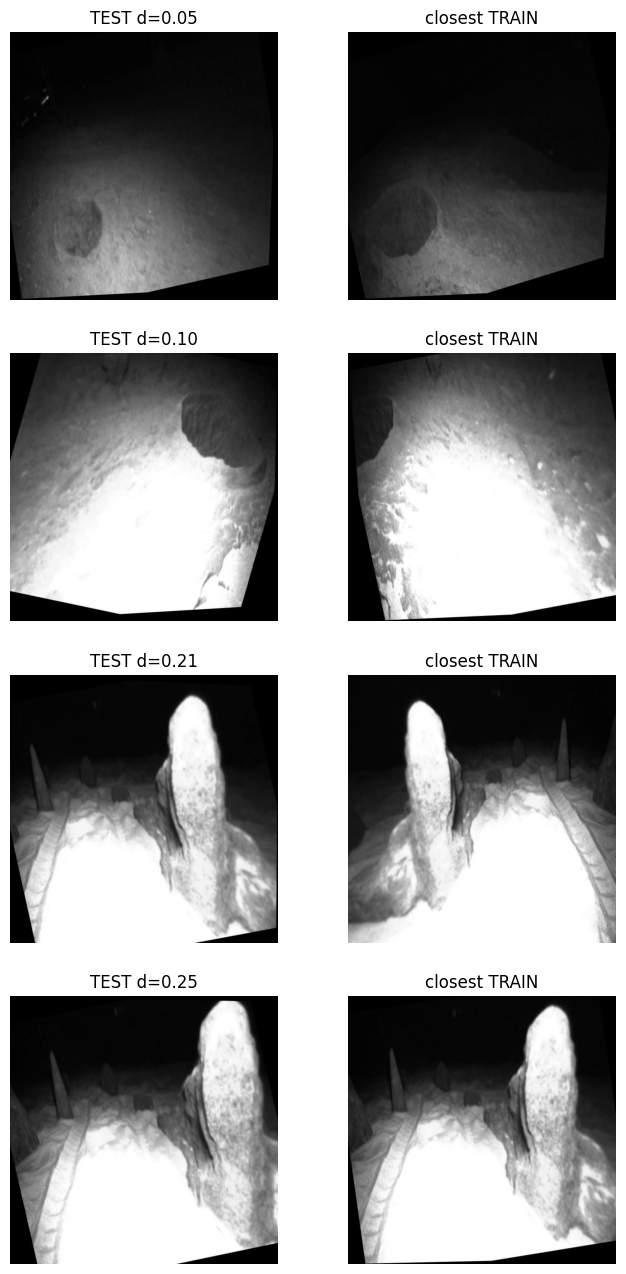

In [30]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

R = Path("/content/rc/Dataset_clean")
tr_paths = sorted((R/"train"/"images").glob("*"))
te_paths = sorted((R/"test"/"images").glob("*"))

if len(tr_paths) > 0 and len(te_paths) > 0:
    # Re-calculate vectors and distance mappings for the updated split
    def vec(p):
        a = np.asarray(Image.open(p).convert("L").resize((24, 24)), dtype=np.float32)
        return (a - a.mean()) / (a.std() + 1e-6)

    tr = np.stack([vec(p).ravel() for p in tr_paths])

    res = []
    for p in te_paths:
        a = vec(p)
        d = np.minimum(np.mean((tr - a.ravel())**2, axis=1), np.mean((tr - a[:, ::-1].ravel())**2, axis=1))
        i = int(d.argmin())
        res.append((float(d[i]), p, tr_paths[i]))
    res.sort(key=lambda r: r[0])

    ds = np.array([r[0] for r in res])
    for t in [0.02, 0.05, 0.1, 0.2, 0.3]:
        print(t, int((ds < t).sum()))

    fig, ax = plt.subplots(4, 2, figsize=(8, 16))
    for row, t in enumerate([0.05, 0.1, 0.2, 0.3]):
        k = int(np.abs(ds - t).argmin())
        d, tp, rp = res[k]
        ax[row][0].imshow(Image.open(tp))
        ax[row][0].set_title(f"TEST d={d:.2f}")
        ax[row][1].imshow(Image.open(rp))
        ax[row][1].set_title("closest TRAIN")
    for a in ax.ravel():
        a.axis("off")
    plt.show()
else:
    print("Verify dataset paths: no clean split images found in train/test splits.")

In [31]:
import torch, torchvision
from torchvision import transforms as T
net = torchvision.models.resnet50(weights="IMAGENET1K_V2").cuda().eval()
net.fc = torch.nn.Identity()
prep = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
E = []
with torch.no_grad():
    for i in range(0, len(paths), 64):
        batch = torch.stack([prep(Image.open(p).convert("RGB")) for p in paths[i:i+64]]).cuda()
        E.append(net(batch).cpu())
E = torch.nn.functional.normalize(torch.cat(E), dim=1).numpy()
print(E.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 113MB/s]


(8354, 2048)


In [32]:
idx = {p.name: i for i, p in enumerate(paths)}
same = np.array([float(E[idx[tp.name]] @ E[idx[rp.name]]) for d, tp, rp in res])
rng = np.random.default_rng(0)
a = rng.integers(0, len(paths), 5000); b = rng.integers(0, len(paths), 5000)
rand = (E[a] * E[b]).sum(1)
print("same-scene pairs (d<0.3): min %.2f | median %.2f" % (same[ds < 0.3].min(), np.median(same[ds < 0.3])))
print("random pairs: median %.2f | 99th percentile %.2f" % (np.median(rand), np.percentile(rand, 99)))

same-scene pairs (d<0.3): min 0.55 | median 0.92
random pairs: median 0.72 | 99th percentile 0.93


In [33]:
import cv2
sift = cv2.SIFT_create(nfeatures=500)
bf = cv2.BFMatcher()
def feats(p, flip=False):
    g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (320, 320))
    if flip: g = cv2.flip(g, 1)
    return sift.detectAndCompute(g, None)
def inliers(p, q, flip=False):
    k1, d1 = feats(p); k2, d2 = feats(q, flip)
    if d1 is None or d2 is None or len(k1) < 8 or len(k2) < 8: return 0
    m = [x[0] for x in bf.knnMatch(d1, d2, k=2) if len(x) == 2 and x[0].distance < 0.75 * x[1].distance]
    if len(m) < 8: return 0
    src = np.float32([k1[a.queryIdx].pt for a in m]); dst = np.float32([k2[a.trainIdx].pt for a in m])
    H, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=5)
    return 0 if mask is None else int(mask.sum())
score = lambda p, q: max(inliers(p, q), inliers(p, q, True))
sample = [res[i] for i in np.linspace(0, len(res) - 1, 30).astype(int)]
print("closest pairs:", [(round(d, 2), score(tp, rp)) for d, tp, rp in sample])
pr = rng.integers(0, len(paths), (30, 2))
print("random pairs:", [score(paths[i], paths[j]) for i, j in pr])

closest pairs: [(0.02, 51), (0.02, 47), (0.02, 6), (0.02, 8), (0.02, 15), (0.03, 31), (0.03, 53), (0.03, 0), (0.03, 33), (0.03, 0), (0.03, 0), (0.03, 0), (0.03, 317), (0.03, 0), (0.03, 65), (0.03, 50), (0.03, 0), (0.03, 0), (0.04, 0), (0.04, 8), (0.04, 26), (0.04, 0), (0.04, 22), (0.05, 4), (0.05, 67), (0.05, 8), (0.06, 22), (0.06, 81), (0.07, 45), (0.25, 175)]
random pairs: [0, 3, 0, 0, 0, 0, 17, 0, 0, 0, 0, 0, 10, 0, 0, 0, 0, 0, 0, 0, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0]


In [34]:
import cv2
sift = cv2.SIFT_create(nfeatures=500)
K, D, Kf, Df = [], [], [], []
def pack(g):
    k, d = sift.detectAndCompute(g, None)
    if d is None: return np.zeros((0, 2), np.float32), np.zeros((0, 128), np.uint8)
    return np.float32([x.pt for x in k]), d.astype(np.uint8)
for p in paths:
    g = cv2.resize(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), (320, 320))
    a, b = pack(g); c, e = pack(cv2.flip(g, 1))
    K.append(a); D.append(b); Kf.append(c); Df.append(e)
print(sum(len(k) == 0 for k in K), "images with no keypoints")
S = E @ E.T
np.fill_diagonal(S, -1)
nbr = np.argsort(-S, axis=1)[:, :15]
hit = [int(idx[rp.name] in nbr[idx[tp.name]]) for d, tp, rp in sample]
print(sum(hit), "of", len(hit), "known pairs are in the top-15 list")

7 images with no keypoints
9 of 30 known pairs are in the top-15 list


In [35]:
sq = (X ** 2).sum(1)
P = np.zeros((len(X), 15), dtype=np.int64)

In [36]:
for i in range(0, len(X), 500):
    d1 = (sq[i:i+500, None] + sq[None, :] - 2 * X[i:i+500] @ X.T) / X.shape[1]
    d2 = (sq[i:i+500, None] + sq[None, :] - 2 * X[i:i+500] @ Xf.T) / X.shape[1]
    d = np.minimum(d1, d2)

In [37]:
    d[np.arange(d.shape[0]), np.arange(i, i + d.shape[0])] = 1e9
    P[i:i+500] = np.argsort(d, axis=1)[:, :15]

In [38]:
pairs = {(min(i, int(j)), max(i, int(j))) for i in range(len(X)) for j in np.concatenate([nbr[i], P[i]])}
print(len(pairs), "candidate pairs")

95610 candidate pairs


In [39]:
import time
bf = cv2.BFMatcher()

In [40]:
def match_count(k1, d1, k2, d2):
    if len(d1) < 8 or len(d2) < 8: return 0
    m = [x[0] for x in bf.knnMatch(d1.astype(np.float32), d2.astype(np.float32), k=2)
         if len(x) == 2 and x[0].distance < 0.75 * x[1].distance]
    if len(m) < 8: return 0
    src = k1[[a.queryIdx for a in m]]; dst = k2[[a.trainIdx for a in m]]
    H, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=5)
    return 0 if mask is None else int(mask.sum())

In [41]:
sc = {}; t0 = time.time()
for n, (i, j) in enumerate(sorted(pairs)):
    s = match_count(K[i], D[i], K[j], D[j])
    if s < 25: s = max(s, match_count(K[i], D[i], Kf[j], Df[j]))
    sc[(i, j)] = s
    if n % 10000 == 0: print(n, round(time.time() - t0), "s")

0 0 s
10000 9 s
20000 18 s
30000 29 s
40000 38 s
50000 49 s
60000 61 s
70000 71 s
80000 81 s
90000 89 s


In [42]:
print(sum(v >= 25 for v in sc.values()), "pairs matched out of", len(sc), "|", round(time.time() - t0), "s")

49395 pairs matched out of 95610 | 95 s


In [43]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
ij = np.array(sorted(pairs))
ssift = np.array([sc[(int(i), int(j))] for i, j in ij])
dpx = np.minimum(((X[ij[:, 0]] - X[ij[:, 1]]) ** 2).mean(1), ((X[ij[:, 0]] - Xf[ij[:, 1]]) ** 2).mean(1))
link = (ssift >= 25) | (dpx < 0.02)
print(link.sum(), "links")
G = coo_matrix((np.ones(link.sum()), (ij[link, 0], ij[link, 1])), shape=(len(X), len(X)))
ngroups, label = connected_components(G, directed=False)
sizes = np.bincount(label)
print(ngroups, "groups | biggest:", sizes.max(), "| images in groups >200:", sizes[sizes > 200].sum())


56684 links
905 groups | biggest: 1520 | images in groups >200: 7042


In [44]:
import shutil
from collections import Counter
SRC = Path("/content/rc/Dataset_yolo")
DST = Path("/content/rc/Dataset_clean")
assert len({p.name for p in paths}) == len(paths)
tot = len(paths)
target = {"train": 0.8 * tot, "valid": 0.1 * tot, "test": 0.1 * tot}
got = {"train": 0, "valid": 0, "test": 0}
split_of_group = {}
for g in np.argsort(-sizes):
    s = max(target, key=lambda k: target[k] - got[k])
    split_of_group[int(g)] = s
    got[s] += int(sizes[g])
print(got)
shutil.rmtree(DST, ignore_errors=True)
for s in ["train", "valid", "test"]:
    (DST/s/"images").mkdir(parents=True); (DST/s/"labels").mkdir(parents=True)
for p, g in zip(paths, label):
    d = split_of_group[int(g)]
    lab = SRC/p.parent.parent.name/"labels"/(p.stem + ".txt")
    shutil.copy(p, DST/d/"images"/p.name)
    if lab.exists(): shutil.copy(lab, DST/d/"labels"/lab.name)
for s in ["train", "valid", "test"]:
    c = Counter(int(l.split()[0]) for f in (DST/s/"labels").glob("*.txt") for l in open(f) if l.strip())
    print(s, len(list((DST/s/"images").glob("*"))), "images | boxes:", dict(c))


{'train': 6683, 'valid': 836, 'test': 835}
train 6683 images | boxes: {1: 14489, 0: 4305}
valid 836 images | boxes: {1: 901, 0: 1491}
test 835 images | boxes: {1: 1324, 0: 918}


In [45]:
spl = np.array([{"train": 0, "valid": 1, "test": 2}[split_of_group[int(g)]] for g in label])
cross = spl[ij[:, 0]] != spl[ij[:, 1]]
for t in [10, 15, 20, 25]:
    print(t, int(((ssift >= t) & cross).sum()))

10 2975
15 1410
20 374
25 0


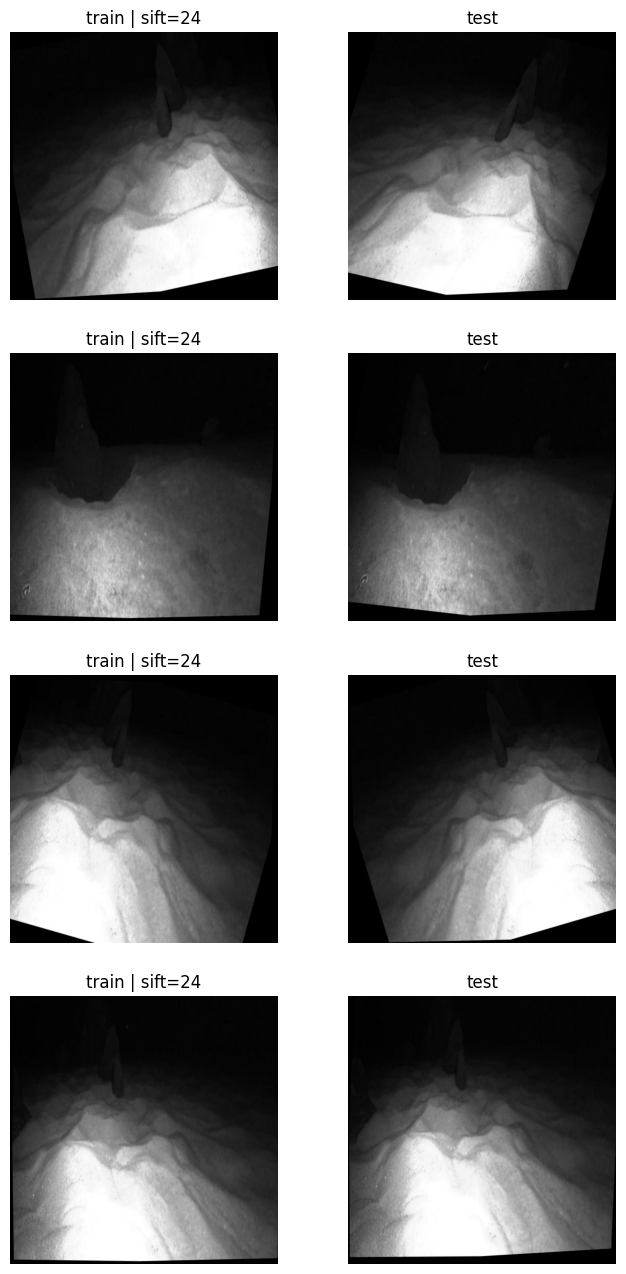

In [46]:
import matplotlib.pyplot as plt
from PIL import Image
names = ["train", "valid", "test"]
sus = np.where(cross)[0]
sus = sus[np.argsort(-ssift[sus])][:4]
fig, ax = plt.subplots(4, 2, figsize=(8, 16))
for r, k in enumerate(sus):
    a, b = ij[k]
    ax[r][0].imshow(Image.open(paths[a])); ax[r][0].set_title(f"{names[spl[a]]} | sift={ssift[k]}")
    ax[r][1].imshow(Image.open(paths[b])); ax[r][1].set_title(f"{names[spl[b]]}")
for a in ax.ravel(): a.axis("off")
plt.show()

In [47]:
link = (ssift >= 12) | (dpx < 0.02)
print(link.sum(), "links")
G = coo_matrix((np.ones(link.sum()), (ij[link, 0], ij[link, 1])), shape=(len(X), len(X)))
ngroups, label = connected_components(G, directed=False)
sizes = np.bincount(label)
print(ngroups, "groups | biggest:", sizes.max(), "| images in groups >200:", sizes[sizes > 200].sum())

70972 links
270 groups | biggest: 6318 | images in groups >200: 7953


In [48]:
import shutil, yaml
from collections import Counter
SRC = Path("/content/rc/Dataset_yolo")
DST = Path("/content/rc/Dataset_clean")
assert len({p.name for p in paths}) == len(paths)
tot = len(paths)
target = {"train": 0.8 * tot, "valid": 0.1 * tot, "test": 0.1 * tot}
got = {"train": 0, "valid": 0, "test": 0}
split_of_group = {}
for g in np.argsort(-sizes):
    s = max(target, key=lambda k: target[k] - got[k])
    split_of_group[int(g)] = s
    got[s] += int(sizes[g])
print(got)
shutil.rmtree(DST, ignore_errors=True)
for s in ["train", "valid", "test"]:
    (DST/s/"images").mkdir(parents=True); (DST/s/"labels").mkdir(parents=True)
for p, g in zip(paths, label):
    d = split_of_group[int(g)]
    lab = SRC/p.parent.parent.name/"labels"/(p.stem + ".txt")
    shutil.copy(p, DST/d/"images"/p.name)
    if lab.exists(): shutil.copy(lab, DST/d/"labels"/lab.name)
yaml.safe_dump({"path": str(DST), "train": "train/images", "val": "valid/images", "test": "test/images",
                "nc": 2, "names": ["crater", "rock"]}, open("/content/rc/rocks_clean.yaml", "w"))
for s in ["train", "valid", "test"]:
    c = Counter(int(l.split()[0]) for f in (DST/s/"labels").glob("*.txt") for l in open(f) if l.strip())
    print(s, len(list((DST/s/"images").glob("*"))), "images | boxes:", dict(c))

{'train': 6318, 'valid': 1635, 'test': 401}
train 6318 images | boxes: {1: 11102, 0: 6105}
valid 1635 images | boxes: {1: 5098}
test 401 images | boxes: {0: 609, 1: 514}


In [49]:
spl = np.array([{"train": 0, "valid": 1, "test": 2}[split_of_group[int(g)]] for g in label])
cross = spl[ij[:, 0]] != spl[ij[:, 1]]
for t in [8, 10, 12, 15, 20, 25]:
    print(t, int(((ssift >= t) & cross).sum()))
print("pixel-close pairs across splits:", int(((dpx < 0.02) & cross).sum()))

8 316
10 91
12 0
15 0
20 0
25 0
pixel-close pairs across splits: 0


In [50]:
def unseen_matches(split_id):
    q = np.where(spl == split_id)[0]; t_idx = np.where(spl == 0)[0]
    Xq, Xt = X[q], X[t_idx]
    sq_q, sq_t = (Xq ** 2).sum(1), (Xt ** 2).sum(1)
    dp = np.minimum(sq_q[:, None] + sq_t[None, :] - 2 * Xq @ Xt.T,
                    sq_q[:, None] + sq_t[None, :] - 2 * Xq @ Xf[t_idx].T) / X.shape[1]
    top_p = np.argsort(dp, axis=1)[:, :50]
    top_r = np.argsort(-(E[q] @ E[t_idx].T), axis=1)[:, :50]
    bad = []
    for a, i in enumerate(q):
        for j in set(t_idx[top_p[a]]) | set(t_idx[top_r[a]]):
            s = match_count(K[i], D[i], K[j], D[j])
            s = max(s, match_count(K[i], D[i], Kf[j], Df[j]))
            if s >= 12:
                bad.append(int(i)); break
    return q, bad

q_valid, bad_valid = unseen_matches(1)
q_test, bad_test = unseen_matches(2)
print("valid:", len(bad_valid), "of", len(q_valid), "| test:", len(bad_test), "of", len(q_test), "have a SIFT match >= 12 with a train image")

valid: 255 of 1635 | test: 155 of 401 have a SIFT match >= 12 with a train image


In [51]:
for i in bad_valid + bad_test:
    d = ["train", "valid", "test"][spl[i]]
    (DST/d/"images"/paths[i].name).unlink(missing_ok=True)
    (DST/d/"labels"/(paths[i].stem + ".txt")).unlink(missing_ok=True)
for s in ["train", "valid", "test"]:
    print(s, len(list((DST/s/"images").glob("*"))), "images")

train 6318 images
valid 1380 images
test 246 images


In [52]:
from ultralytics import YOLO
model = YOLO("yolov8s.pt")
_ = model.train(data="/content/rc/rocks_clean.yaml", epochs=30, imgsz=640, batch=16, patience=10,
                project="/content/drive/MyDrive/paradox/checkpoints", name="yolov8s_rocks_clean", exist_ok=True)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rc/rocks_clean.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_rocks_clean, nbs=64, nms=None, opset=None, optimize=Fa

In [53]:
m_clean = YOLO("/content/drive/MyDrive/paradox/checkpoints/yolov8s_rocks_clean/weights/best.pt")
r = m_clean.val(data="/content/rc/rocks_clean.yaml", split="test")
print("clean test mAP50-95:", round(float(r.box.map), 3), "| mAP50:", round(float(r.box.map50), 3))
print({r.names[k]: round(float(v), 3) for k, v in zip(r.box.ap_class_index, r.box.maps[r.box.ap_class_index])})

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 682.5±200.0 MB/s, size: 18.5 KB)
val: Scanning /content/rc/Dataset_clean/test/labels... 246 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 246/246 1.5Kit/s 0.2s
val: New cache created: /content/rc/Dataset_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 2.7it/s 5.8s
                   all        246        694       0.92      0.951      0.973      0.774
                crater        228        366      0.905      0.943      0.964      0.808
                  rock        192        328      0.935      0.959      0.982      0.741
Speed: 2.6ms preprocess, 10.7ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/val-2
clean test mAP50-95: 0.774 | 

In [54]:
import json
json.dump({p.name: split_of_group[int(g)] for p, g in zip(paths, label)}, open("/content/drive/MyDrive/paradox/rocks_split.json", "w"))
!cd /content/rc && rm -rf stage && mkdir stage && cp -r Dataset_clean stage/Dataset_yolo && cp Dataset_yolo/data.yaml stage/Dataset_yolo/
!cd /content/rc/stage && zip -qr rocks_craters_yolo.zip Dataset_yolo
!cp /content/rc/stage/rocks_craters_yolo.zip /content/drive/MyDrive/paradox/rocks_craters_yolo.zip
!ls -lh /content/rc/stage/rocks_craters_yolo.zip /content/drive/MyDrive/paradox/rocks_craters_yolo.zip

-rw------- 1 root root 169M Oct 11 11:18 /content/drive/MyDrive/paradox/rocks_craters_yolo.zip
-rw-r--r-- 1 root root 169M Oct 11 11:18 /content/rc/stage/rocks_craters_yolo.zip


In [8]:
!mkdir -p /content/rc
!wget -c --tries=10 --timeout=60 -O /content/rc/Dataset_yolo.zip "https://zenodo.org/records/14673237/files/Dataset_yolo.zip?download=1"
!cd /content/rc && unzip -q -o Dataset_yolo.zip
!ls /content/rc/Dataset_yolo

--2026-10-11 12:55:38--  https://zenodo.org/records/14673237/files/Dataset_yolo.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.52.235, 137.138.153.219, 188.185.48.75, ...
Connecting to zenodo.org (zenodo.org)|137.138.52.235|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 186819579 (178M) [application/octet-stream]
Saving to: ‘/content/rc/Dataset_yolo.zip’

/content/rc/Dataset 100%[===================>] 178.16M  1.03MB/s    in 2m 39s  

2026-10-11 12:58:18 (1.12 MB/s) - ‘/content/rc/Dataset_yolo.zip’ saved [186819579/186819579]

data.yaml  test  train	valid


In [9]:
import os, json, zipfile
import numpy as np
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# Fallback to Dataset_clean if Dataset_yolo doesn't exist
R = Path("/content/rc/Dataset_clean" if os.path.exists("/content/rc/Dataset_clean") else "/content/rc/Dataset_yolo")
paths = sorted(p for s in ["train", "valid", "test"] for p in (R/s/"images").glob("*"))

zp = "/content/drive/MyDrive/paradox/rocks_craters_yolo.zip"
train_names = {os.path.basename(n) for n in zipfile.ZipFile(zp).namelist() if "/train/images/" in n and not n.endswith("/")}
spl = np.array([0 if p.name in train_names else 1 for p in paths], dtype=np.int64)
print(f"Found {len(paths)} total images in {R.name}.")
print(len(train_names), np.bincount(spl))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 8354 total images in Dataset_yolo.
6318 [6318 2036]


In [12]:
import numpy as np, cv2, torch, torchvision, time
from pathlib import Path
from PIL import Image
from torchvision import transforms as T

R = Path("/content/rc/Dataset_yolo")
paths = sorted(p for s in ["train", "valid", "test"] for p in (R/s/"images").glob("*"))
assert len(paths) == 8354, len(paths)

def vec(p):
    a = np.asarray(Image.open(p).convert("L").resize((24, 24)), dtype=np.float32)
    return (a - a.mean()) / (a.std() + 1e-6)
A = [vec(p) for p in paths]
X = np.stack([a.ravel() for a in A])
Xf = np.stack([a[:, ::-1].ravel() for a in A])

net = torchvision.models.resnet50(weights="IMAGENET1K_V2").cuda().eval()
net.fc = torch.nn.Identity()
prep = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
E = []
with torch.no_grad():
    for i in range(0, len(paths), 64):
        batch = torch.stack([prep(Image.open(p).convert("RGB")) for p in paths[i:i+64]]).cuda()
        E.append(net(batch).cpu())
E = torch.nn.functional.normalize(torch.cat(E), dim=1).numpy()

sift = cv2.SIFT_create(nfeatures=500)
bf = cv2.BFMatcher()
K, D, Kf, Df = [], [], [], []
def pack(g):
    k, d = sift.detectAndCompute(g, None)
    if d is None: return np.zeros((0, 2), np.float32), np.zeros((0, 128), np.uint8)
    return np.float32([x.pt for x in k]), d.astype(np.uint8)
for p in paths:
    g = cv2.resize(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), (320, 320))
    a, b = pack(g); c, e = pack(cv2.flip(g, 1))
    K.append(a); D.append(b); Kf.append(c); Df.append(e)

S = E @ E.T
np.fill_diagonal(S, -1)
nbr = np.argsort(-S, axis=1)[:, :15]
del S
sq = (X ** 2).sum(1)
P = np.zeros((len(X), 15), dtype=np.int64)
for i in range(0, len(X), 500):
    d1 = (sq[i:i+500, None] + sq[None, :] - 2 * X[i:i+500] @ X.T) / X.shape[1]
    d2 = (sq[i:i+500, None] + sq[None, :] - 2 * X[i:i+500] @ Xf.T) / X.shape[1]
    d = np.minimum(d1, d2)
    d[np.arange(d.shape[0]), np.arange(i, i + d.shape[0])] = 1e9
    P[i:i+500] = np.argsort(d, axis=1)[:, :15]
pairs = {(min(i, int(j)), max(i, int(j))) for i in range(len(X)) for j in np.concatenate([nbr[i], P[i]])}

def match_count(k1, d1, k2, d2):
    if len(d1) < 8 or len(d2) < 8: return 0
    m = [x[0] for x in bf.knnMatch(d1.astype(np.float32), d2.astype(np.float32), k=2)
         if len(x) == 2 and x[0].distance < 0.75 * x[1].distance]
    if len(m) < 8: return 0
    src = k1[[a.queryIdx for a in m]]; dst = k2[[a.trainIdx for a in m]]
    H, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=5)
    return 0 if mask is None else int(mask.sum())

sc = {}
for i, j in sorted(pairs):
    s = match_count(K[i], D[i], K[j], D[j])
    if s < 25: s = max(s, match_count(K[i], D[i], Kf[j], Df[j]))
    sc[(i, j)] = s

ij = np.array(sorted(pairs))
ssift = np.array([sc[(int(i), int(j))] for i, j in ij])
dpx = np.minimum(((X[ij[:, 0]] - X[ij[:, 1]]) ** 2).mean(1), ((X[ij[:, 0]] - Xf[ij[:, 1]]) ** 2).mean(1))
print(len(paths), "images |", len(pairs), "candidate pairs |", int((ssift >= 25).sum()), "matched")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 205MB/s]


8354 images | 144412 candidate pairs | 61306 matched


In [13]:
import time
import numpy as np
import cv2

def match_ok(k1, d1, k2, d2):
    if len(d1) < 8 or len(d2) < 8: return 0
    m = [x[0] for x in bf.knnMatch(d1.astype(np.float32), d2.astype(np.float32), k=2)
         if len(x) == 2 and x[0].distance < 0.75 * x[1].distance]
    if len(m) < 8: return 0
    src = k1[[a.queryIdx for a in m]]; dst = k2[[a.trainIdx for a in m]]
    M, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=5)
    if M is None: return 0
    scale = float(np.hypot(M[0, 0], M[1, 0])); angle = abs(float(np.degrees(np.arctan2(M[1, 0], M[0, 0]))))
    return int(mask.sum()) if 0.6 < scale < 1.7 and angle < 35 else 0

chk = np.random.default_rng(0).choice(np.where(ssift >= 20)[0], 30, replace=False)
ok = [max(match_ok(K[a], D[a], K[b], D[b]), match_ok(K[a], D[a], Kf[b], Df[b])) for a, b in ij[chk]]
print(sum(s >= 12 for s in ok), "of 30 strong pairs still match under the new rule")

t_idx = np.where(spl == 0)[0]
pool = np.where(spl != 0)[0]
Xq, Xt = X[pool], X[t_idx]
sq_q, sq_t = (Xq ** 2).sum(1), (Xt ** 2).sum(1)
dp = np.minimum(sq_q[:, None] + sq_t[None, :] - 2 * Xq @ Xt.T,
                sq_q[:, None] + sq_t[None, :] - 2 * Xq @ Xf[t_idx].T) / X.shape[1]
top_p = np.argsort(dp, axis=1)[:, :60]
top_r = np.argsort(-(E[pool] @ E[t_idx].T), axis=1)[:, :60]

flag = np.zeros(len(pool), dtype=bool); t0 = time.time()
for a, i in enumerate(pool):
    for j in set(t_idx[top_p[a]]) | set(t_idx[top_r[a]]):
        s = max(match_ok(K[i], D[i], K[j], D[j]), match_ok(K[i], D[i], Kf[j], Df[j]))
        if s >= 12:
            flag[a] = True; break
    if a % 500 == 0: print(a, round(time.time() - t0), "s")
print(int(flag.sum()), "of", len(pool), "have a match with train |", int((~flag).sum()), "unseen images left")

30 of 30 strong pairs still match under the new rule
0 0 s
500 17 s
1000 36 s
1500 66 s
2000 86 s
26 of 2036 have a match with train | 2010 unseen images left


In [14]:
dmin = dp.min(1)
for t in [0.02, 0.05, 0.1]:
    print(t, int(((~flag) & (dmin < t)).sum()))


0.02 91
0.05 1640
0.1 1997


In [16]:
!pip -q install ultralytics
import shutil, yaml
from collections import Counter
from pathlib import Path
from ultralytics import YOLO

keep = pool[(~flag) & (dmin >= 0.05)]
EV = Path("/content/rc/Dataset_eval")
shutil.rmtree(EV, ignore_errors=True)
(EV/"test"/"images").mkdir(parents=True); (EV/"test"/"labels").mkdir(parents=True)
for i in keep:
    p = paths[i]
    lab = R/p.parent.parent.name/"labels"/(p.stem + ".txt")
    shutil.copy(p, EV/"test"/"images"/p.name)
    if lab.exists(): shutil.copy(lab, EV/"test"/"labels"/lab.name)
yaml.safe_dump({"path": str(EV), "train": "test/images", "val": "test/images", "test": "test/images",
                "nc": 2, "names": ["crater", "rock"]}, open("/content/rc/rocks_eval.yaml", "w"))
c = Counter(int(l.split()[0]) for f in (EV/"test"/"labels").glob("*.txt") for l in open(f) if l.strip())
print(len(keep), "images | boxes:", dict(c))

m = YOLO("/content/drive/MyDrive/paradox/checkpoints/yolov8s_rocks_clean/weights/best.pt")
r = m.val(data="/content/rc/rocks_eval.yaml", split="test")
print("mAP50-95:", round(float(r.box.map), 3), "| mAP50:", round(float(r.box.map50), 3))
print({r.names[k]: round(float(v), 3) for k, v in zip(r.box.ap_class_index, r.box.maps[r.box.ap_class_index])})

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
370 images | boxes: {1: 1079, 0: 228}
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 760.6±288.9 MB/s, size: 21.7 KB)
val: Scanning /content/rc/Dataset_eval/test/labels... 370 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 370/370 1.6Kit/s 0.2s
val: New cache created: /content/rc/Dataset_eval/test

In [17]:
def eval_at(t):
    keep = pool[(~flag) & (dmin >= t)]
    EV = Path(f"/content/rc/Dataset_eval_{t}")
    shutil.rmtree(EV, ignore_errors=True)
    (EV/"test"/"images").mkdir(parents=True); (EV/"test"/"labels").mkdir(parents=True)
    for i in keep:
        p = paths[i]
        lab = R/p.parent.parent.name/"labels"/(p.stem + ".txt")
        shutil.copy(p, EV/"test"/"images"/p.name)
        if lab.exists(): shutil.copy(lab, EV/"test"/"labels"/lab.name)
    yaml.safe_dump({"path": str(EV), "train": "test/images", "val": "test/images", "test": "test/images",
                    "nc": 2, "names": ["crater", "rock"]}, open(f"/content/rc/rocks_eval_{t}.yaml", "w"))
    r = m.val(data=f"/content/rc/rocks_eval_{t}.yaml", split="test", verbose=False, plots=False)
    return len(keep), round(float(r.box.map), 3), round(float(r.box.map50), 3)

for t in [0.0, 0.02, 0.05]:
    print("min pixel distance", t, "-> images, mAP50-95, mAP50:", eval_at(t))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 687.4±306.2 MB/s, size: 21.0 KB)
val: Scanning /content/rc/Dataset_eval_0.0/test/labels... 2010 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2010/2010 433.4it/s 4.6s
val: New cache created: /content/rc/Dataset_eval_0.0/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 126/126 4.3it/s 29.0s
                   all       2010       6155      0.917      0.918      0.955      0.808
Speed: 1.0ms preprocess, 10.4ms inference, 0.0ms loss, 0.9ms postprocess per image
min pixel distance 0.0 -> images, mAP50-95, mAP50: (2010, 0.808, 0.955)
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs


## Model, data leakage and clean evaluation: before vs after

### Model
- **YOLOv8s (Ultralytics)**, initialised from COCO-pretrained `yolov8s.pt`, 2 classes (crater, rock), ~11.1M parameters.
- Why: a small single-stage detector that is fast enough to run on a rover, gives bounding boxes (needed for rock/crater detection), and transfers well from pretrained weights.
- Training setup (identical before and after the fix): 30 epochs, `patience=10`, image size 640, batch 16, AdamW (auto), T4 GPU, about 1 hour per run.

### What went wrong: data leakage
- The dataset (Zenodo `Dataset_yolo`, 8354 images) contains many augmented copies (rotated, cropped, flipped) of the same scenes, and the augmentation was applied before the train/valid/test split.
- Evidence: 249 of 268 test source images also exist in train (same source file name), and every test image (307 of 307) had a near-identical train image.
- Result: the first model scored 0.912 mAP50-95 on a test set it had effectively already seen.

### What we tried to find the duplicates
| Method | Outcome |
|---|---|
| Group by source file name | Not enough: identical scenes appear under different names |
| 24x24 pixel fingerprint | Misses rotated / cropped copies |
| ResNet50 embeddings | Cannot separate same-scene copies from different scenes (all images are dark, grey, similar terrain) |
| SIFT keypoints + RANSAC | Works: rotation/scale invariant. Combined with a pixel check for dark images with no keypoints |

### The fix
- Linked images that show the same scene (SIFT match with a plausible rotation/scale, or near-identical pixels) and grouped them.
- Train = the largest group (6318 images). The other 2036 images were held out.
- From the held-out images we removed any that still matched a train image: 26 by SIFT, 91 by pixel check. Final clean evaluation set: **1919 images**.
- Re-trained the same YOLOv8s on the 6318 train images (best checkpoint: `yolov8s_rocks_clean`).

### Results (mAP50-95 / mAP50)
| Run | Evaluated on | mAP50-95 | mAP50 |
|---|---|---|---|
| Before: original split (leaky) | original test, 307 images | 0.912 | - |
| After: re-split, first attempt | 246 test images | 0.774 | 0.973 |
| After: clean evaluation set | 2010 held-out images | 0.808 | 0.955 |
| After: clean evaluation set | 1919 images (after pixel check) | 0.811 | 0.960 |
| After: strictest set | 370 images | 0.798 | 0.967 |

- Per class on the strictest set: crater 0.825, rock 0.771 (mAP50-95).
- The score stays about 0.80 even when the evaluation is made stricter, so the remaining leakage, if any, does not drive the result.

### Conclusion and limitations
- The honest performance is about **0.80 mAP50-95** (about 0.96 mAP50). The earlier 0.912 was inflated by leakage.
- The held-out images come from a small number of scenes, so the exact value may move a little.
- The thresholds (12 SIFT inliers, scale 0.6 to 1.7, rotation under 35 degrees, pixel distance 0.02) were chosen by inspecting image pairs, not tuned on a labelled duplicate set.
- The validation set used during training had rock only (no craters), so best-epoch selection ignored craters. The best epoch was the last one, so the effect is small.

In [18]:
import json
final_eval = (~flag) & (dmin >= 0.02)
role = {p.name: "train" for p, s in zip(paths, spl) if s == 0}
for i, ok_ in zip(pool, final_eval):
    role[paths[i].name] = "eval" if ok_ else "dropped"
json.dump(role, open("/content/drive/MyDrive/paradox/rocks_split.json", "w"))
print(Counter(role.values()))
!cp /content/rc/Dataset_yolo.zip /content/drive/MyDrive/paradox/rocks_craters_yolo.zip
!mv /content/drive/MyDrive/paradox/checkpoints/yolov8s_rocks /content/drive/MyDrive/paradox/checkpoints/yolov8s_rocks_LEAKY
!ls /content/drive/MyDrive/paradox/checkpoints

Counter({'train': 6318, 'eval': 1919, 'dropped': 117})
yolo_smoke  yolov8s_rocks_clean  yolov8s_rocks_LEAKY
